# Parte 1. Imputación y manejo de datos faltantes

Esta parte se apoya en lo que encontraron la S1 y la S2. La S1 identificó 582 filas incompletas (13,7 %) y siete
variables con faltantes; la más afectada es `glucose` (9,2 %). También mostró que los 29 faltantes de `cigsPerDay`
son todos de fumadores. La S2 validó como estables las correlaciones PAS–PAD, edad–PAS e IMC–PAD, y recomendó
ajustar cualquier imputación solo con el conjunto de entrenamiento.

La S1 no aplicó una prueba formal para clasificar el mecanismo de los faltantes (MCAR, MAR o MNAR), así que no se
puede afirmar que sean MAR. Se adopta MAR como supuesto de trabajo: la ausencia de `cigsPerDay` depende de una
variable observada (`currentSmoker`) y los demás faltantes se pueden modelar con otras covariables. Comparar las
tres estrategias sirve como análisis de sensibilidad frente a ese supuesto.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import display

from utils_s3 import (
    cargar_datos, resumen_faltantes, imputar_simple, imputar_regresion,
    comparar_distribuciones, comparar_correlaciones
)

BASE = Path('.')
DATOS_SALIDA = BASE / 'datos'
TABLAS = BASE / 'tablas'
FIGURAS = BASE / 'figuras'
for ruta in (DATOS_SALIDA, TABLAS, FIGURAS):
    ruta.mkdir(exist_ok=True)
sns.set_theme(style='whitegrid', context='notebook')

## 1.1 Faltantes según la S1

No se repite el análisis exploratorio; solo se recuperan los conteos que se usan para tomar las decisiones de la
S3.

,n_faltantes,porcentaje_faltantes
glucose,388,9.151
education,105,2.476
BPMeds,53,1.250
totChol,50,1.179
cigsPerDay,29,0.684
BMI,19,0.448
heartRate,1,0.024


Filas con al menos un faltante: 582 (13.7 %)


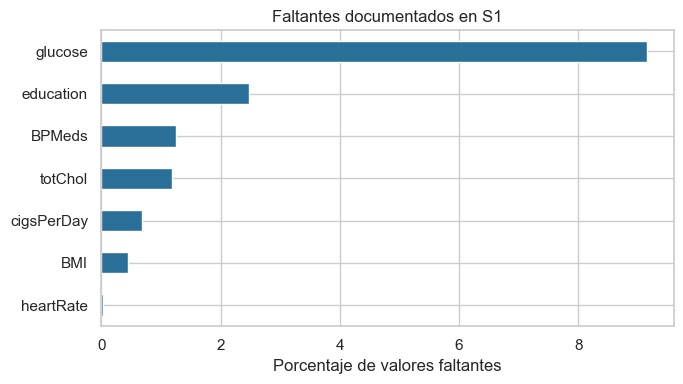

In [2]:
original = cargar_datos()
faltantes = resumen_faltantes(original)
faltantes.to_csv(TABLAS / 'p1_faltantes_s1.csv')
display(faltantes.round(3))
print(f'Filas con al menos un faltante: {original.isna().any(axis=1).sum()} ({100*original.isna().any(axis=1).mean():.1f} %)')

ax = faltantes.sort_values('porcentaje_faltantes')['porcentaje_faltantes'].plot.barh(
    figsize=(7, 4), color='#2A6F97'
)
ax.set(xlabel='Porcentaje de valores faltantes', ylabel='', title='Faltantes documentados en S1')
plt.tight_layout()
plt.savefig(FIGURAS / 'p1_fig1_faltantes.png', dpi=180)
plt.show()

## 1.2 Imputación por regresión lineal múltiple

`imputar_regresion()`, en `utils_s3.py`, ajusta una regresión para cada variable numérica con faltantes, usando
las observaciones completas y entre 3 y 5 predictores. Se priorizan las correlaciones estables de la S2 y nunca se
usa `TenYearCHD` como predictor. Las predicciones se limitan al rango observado, y la mediana solo se usa si a una
fila le faltan los predictores.

El desempeño se mide con una validación 80/20 dentro de los casos completos, y los supuestos se revisan con
Jarque-Bera, Breusch-Pagan, VIF y distancia de Cook. Una imputación con un R² modesto igual sirve para conservar el
tamaño de la muestra, pero esa limitación hay que declararla.

In [3]:
regresion, estado_regresion, diagnosticos, conteos = imputar_regresion(
    original, devolver_detalle=True
)
diagnosticos.to_csv(TABLAS / 'p1_diagnosticos_imputacion.csv', index=False)
conteos.to_csv(TABLAS / 'p1_conteos_imputados.csv', index=False)
display(conteos.fillna('').style.format(precision=0))
display(diagnosticos.style.format({
    'R2_validacion': '{:.3f}', 'RMSE_validacion': '{:.3f}',
    'MAE_validacion': '{:.3f}', 'JB_p_residuos': '{:.3g}',
    'BP_p_heterocedasticidad': '{:.3g}', 'VIF_max': '{:.2f}',
    'Cook_max': '{:.3f}'
}))
assert regresion.isna().sum().sum() == 0

,variable,n_imputados,metodo,n_por_regresion,n_respaldo_mediana
0,education,105,moda,,
1,BPMeds,53,moda,,
2,cigsPerDay,29,regresion lineal multiple,29,0
3,totChol,50,regresion lineal multiple,50,0
4,BMI,19,regresion lineal multiple,19,0
5,heartRate,1,regresion lineal multiple,1,0
6,glucose,388,regresion lineal multiple,388,0


,variable,n_ajuste,predictores,R2_validacion,RMSE_validacion,MAE_validacion,JB_p_residuos,BP_p_heterocedasticidad,VIF_max,Cook_max
0,cigsPerDay,4211,"currentSmoker, age, male, sysBP, diaBP",0.619,7.490,4.662,0,1.68e-127,3.08,0.011
1,totChol,4190,"age, sysBP, diaBP, male, currentSmoker",0.105,42.778,33.436,0,0.00835,3.08,0.026
2,BMI,4221,"diaBP, sysBP, age, male, currentSmoker",0.148,3.569,2.746,4.63e-295,1.26e-45,3.11,0.034
3,heartRate,4239,"age, sysBP, diaBP, male, currentSmoker",0.088,11.477,8.973,1.22e-96,1.18e-06,3.10,0.016
4,glucose,3827,"age, diabetes, sysBP, diaBP, cigsPerDay",0.456,20.796,11.672,0,7.39e-243,3.06,0.283


Los cigarrillos por día son la variable que mejor se imputa, porque `currentSmoker` la explica casi directamente.
En colesterol, IMC, frecuencia cardíaca y glucosa el error es mayor, y los residuos no cumplen normalidad ni
homocedasticidad, en parte por la asimetría que ya se vio en la S1 y la S2. Por eso los valores imputados no se
deben leer como mediciones individuales exactas: sirven para conservar la estructura de los datos en el
modelamiento, y las conclusiones se contrastan con la eliminación y la imputación simple.

## 1.3 Construcción y comparación de las tres estrategias

1. **Eliminación completa:** conserva solo filas sin faltantes.  
2. **Imputación simple:** mediana para numéricas y moda para categóricas.  
3. **Imputación por regresión:** regresiones múltiples para numéricas y moda para categóricas.

In [4]:
eliminacion = original.dropna().copy()
simple = imputar_simple(original)
datasets = {'eliminacion': eliminacion, 'simple': simple, 'regresion': regresion}

for nombre, df in datasets.items():
    df.to_csv(DATOS_SALIDA / f'framingham_{nombre}.csv', index=False)

tamanos = pd.DataFrame([
    {
        'estrategia': nombre, 'n': len(df),
        'filas_perdidas': len(original) - len(df),
        'eventos_CHD': int(df['TenYearCHD'].sum()),
        'tasa_CHD': df['TenYearCHD'].mean()
    }
    for nombre, df in datasets.items()
])
distribuciones = comparar_distribuciones(original, datasets)
correlaciones = comparar_correlaciones(datasets)
tamanos.to_csv(TABLAS / 'p1_comparacion_tamanos.csv', index=False)
distribuciones.to_csv(TABLAS / 'p1_comparacion_distribuciones.csv', index=False)
correlaciones.to_csv(TABLAS / 'p1_preservacion_correlaciones.csv', index=False)
display(tamanos.style.format({'tasa_CHD': '{:.3%}'}))
display(distribuciones.round(3))
display(correlaciones.round(4))

,estrategia,n,filas_perdidas,eventos_CHD,tasa_CHD
0,eliminacion,3658,582,557,15.227%
1,simple,4240,0,644,15.189%
2,regresion,4240,0,644,15.189%


,estrategia,variable,n,media,DE,mediana,IQR,media_original_disponible
0,eliminacion,cigsPerDay,3658,9.025,11.922,0.000,20.000,9.006
1,eliminacion,totChol,3658,236.848,44.098,234.000,57.000,236.700
2,eliminacion,BMI,3658,25.783,4.066,25.380,4.958,25.801
3,eliminacion,heartRate,3658,75.731,11.982,75.000,14.000,75.879
4,eliminacion,glucose,3658,81.853,23.904,78.000,16.000,81.964
5,simple,cigsPerDay,4240,8.944,11.905,0.000,20.000,9.006
6,simple,totChol,4240,236.668,44.328,234.000,56.000,236.700
7,simple,BMI,4240,25.799,4.071,25.400,4.955,25.801
8,simple,heartRate,4240,75.879,12.024,75.000,15.000,75.879
9,simple,glucose,4240,81.601,22.860,78.000,13.000,81.964


,estrategia,par,correlacion,diferencia_vs_regresion
0,eliminacion,sysBP - diaBP,0.7867,0.0027
1,eliminacion,age - sysBP,0.3883,-0.0058
2,eliminacion,BMI - diaBP,0.3853,0.0072
3,eliminacion,totChol - glucose,0.0499,0.0049
4,eliminacion,cigsPerDay - glucose,-0.0537,0.0024
5,simple,sysBP - diaBP,0.7840,0.0000
6,simple,age - sysBP,0.3941,0.0000
7,simple,BMI - diaBP,0.3764,-0.0018
8,simple,totChol - glucose,0.0457,0.0007
9,simple,cigsPerDay - glucose,-0.0568,-0.0007


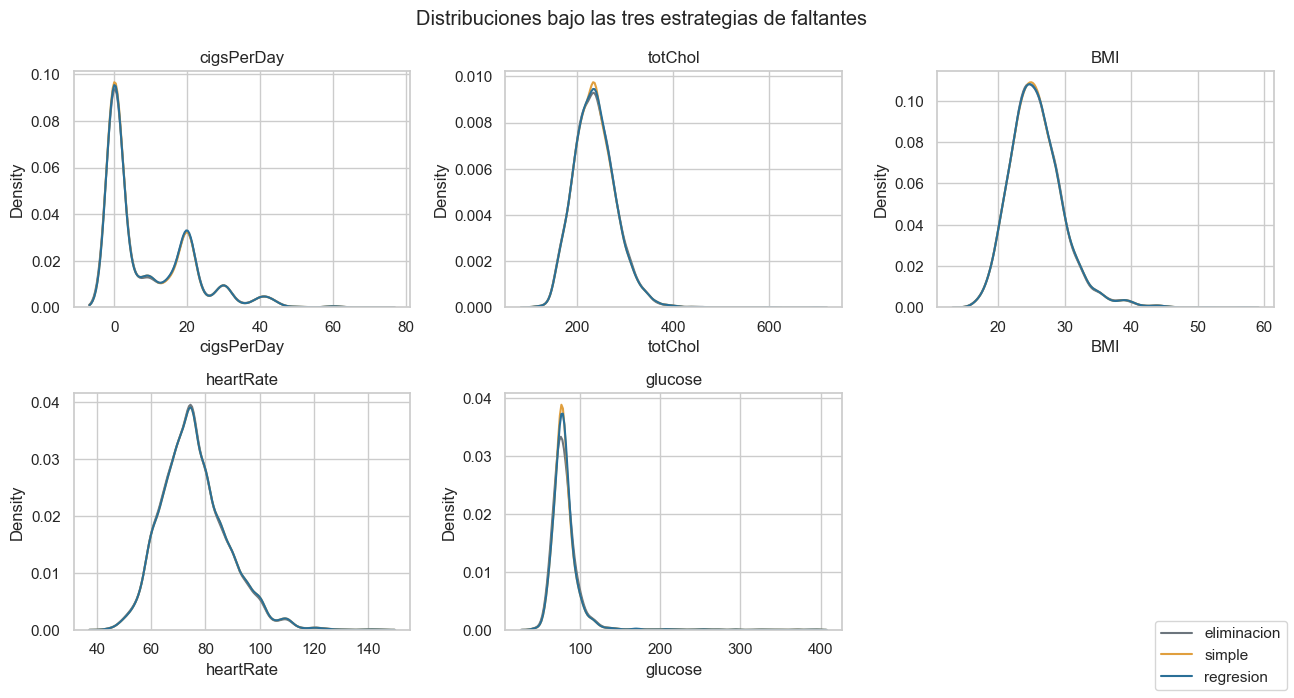

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
variables = ['cigsPerDay', 'totChol', 'BMI', 'heartRate', 'glucose']
colores = {'eliminacion': '#6C757D', 'simple': '#E09F3E', 'regresion': '#2A6F97'}
for ax, variable in zip(axes.ravel(), variables):
    for nombre, df in datasets.items():
        sns.kdeplot(df[variable], ax=ax, label=nombre, color=colores[nombre], warn_singular=False)
    ax.set_title(variable)
axes.ravel()[-1].axis('off')
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower right')
fig.suptitle('Distribuciones bajo las tres estrategias de faltantes')
fig.tight_layout()
plt.savefig(FIGURAS / 'p1_fig2_distribuciones_imputacion.png', dpi=180, bbox_inches='tight')
plt.show()

## 1.4 Decisión para las partes siguientes

Se elige la imputación por regresión como estrategia principal, porque conserva a los 4.240 participantes y usa
relaciones entre variables respaldadas por la S1 y la S2. La eliminación pierde 582 registros (13,7 %) y 87 casos
de CHD, justo en la clase minoritaria. La imputación simple también conserva el tamaño, pero reduce la variabilidad
al concentrar los valores imputados en la mediana o la moda.

Esto no quiere decir que la regresión reconstruya bien cada medición: los R² modestos y los supuestos que no se
cumplen son la razón para mantener la comparación de sensibilidad de la parte 4. Los tres CSV quedan guardados en
`S3/datos/` para que todo el grupo use exactamente las mismas versiones.